<a href="https://colab.research.google.com/github/Bibatshu95/Hum-to-Harmony/blob/main/notebook/01_hum_to_notes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!for i in 1 2 3 4 5; do ffmpeg -loglevel error -y -i "hum $i.mp4" -vn -ac 1 -ar 22050 "hum_$i.wav"; done
!ls *.wav

hum_1.wav  hum_2.wav  hum_3.wav  hum_4.wav  hum_5.wav


In [4]:
!pip install -q librosa
import numpy as np, librosa
import matplotlib.pyplot as plt

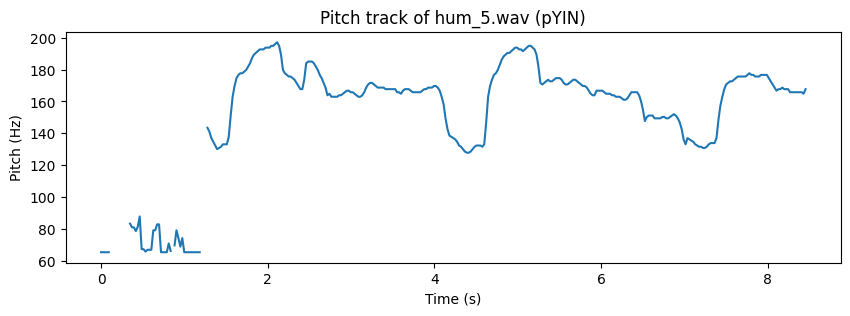

In [15]:
FILE = "hum_5.wav"   # change to hum_2.wav, hum_3.wav ... to check the others

y, sr = librosa.load(FILE, sr=22050)
f0, voiced, _ = librosa.pyin(y, fmin=librosa.note_to_hz("C2"),
                             fmax=librosa.note_to_hz("C6"), sr=sr)
times = librosa.times_like(f0, sr=sr)

plt.figure(figsize=(10, 3))
plt.plot(times, f0)
plt.xlabel("Time (s)"); plt.ylabel("Pitch (Hz)")
plt.title(f"Pitch track of {FILE} (pYIN)")
plt.show()

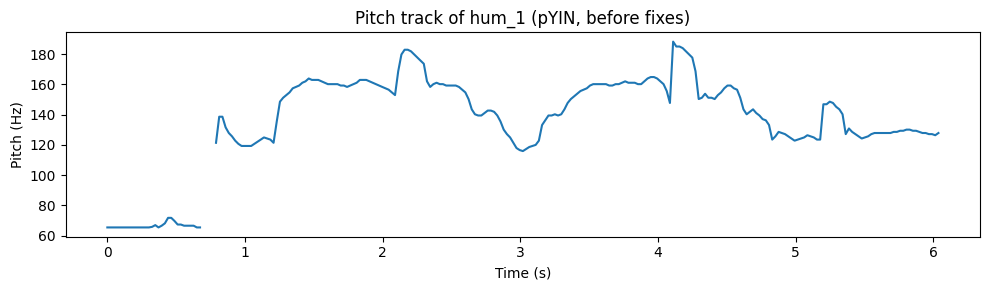

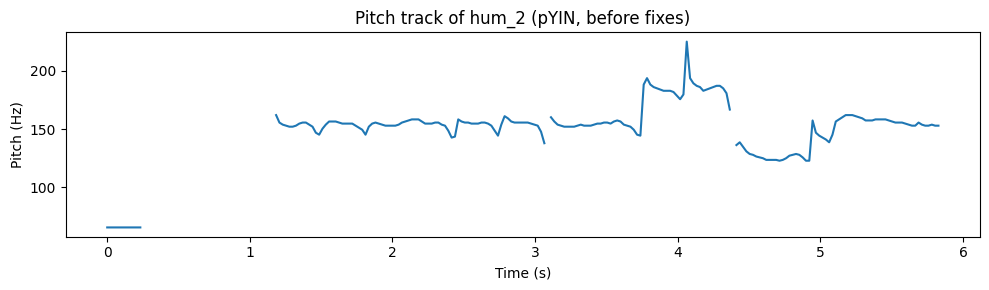

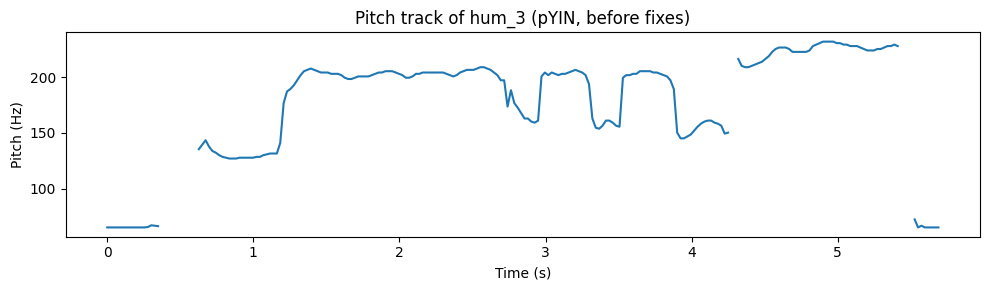

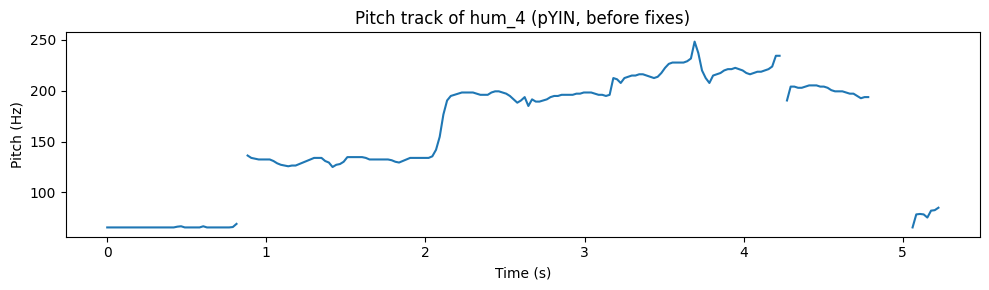

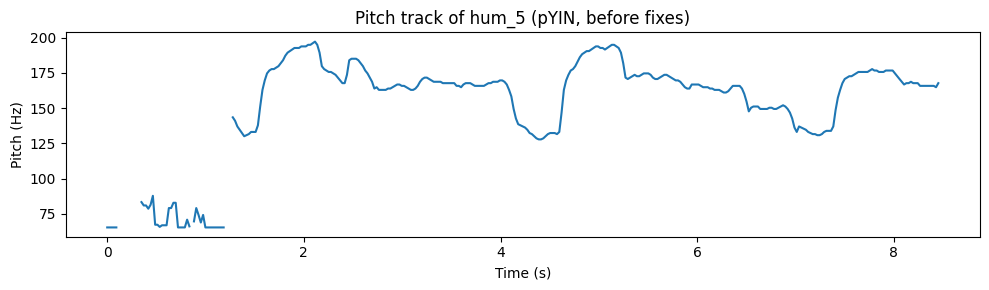

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import os
os.makedirs("outputs", exist_ok=True)

for i in range(1, 6):
    f = f"hum_{i}.wav"
    y, sr = librosa.load(f, sr=22050)
    f0, voiced, _ = librosa.pyin(y, fmin=librosa.note_to_hz("C2"),
                                 fmax=librosa.note_to_hz("C6"), sr=sr)
    times = librosa.times_like(f0, sr=sr)
    plt.figure(figsize=(10, 3))
    plt.plot(times, f0)
    plt.xlabel("Time (s)"); plt.ylabel("Pitch (Hz)")
    plt.title(f"Pitch track of hum_{i} (pYIN, before fixes)")
    plt.tight_layout()
    plt.savefig(f"outputs/pitch_hum_{i}_before.png", dpi=150)
    plt.show()

!zip -q -r outputs.zip outputs
from google.colab import files
files.download("outputs.zip")

In [16]:
midi = np.round(librosa.hz_to_midi(f0))
notes, current, start = [], None, 0.0
MIN_LEN = 0.1

for t, m, v in zip(times, midi, voiced):
    m = int(m) if v and not np.isnan(m) else None
    if m != current:
        if current is not None and t - start >= MIN_LEN:
            notes.append((librosa.midi_to_note(current), round(float(t - start), 2)))
        current, start = m, t
if current is not None:
    notes.append((librosa.midi_to_note(current), round(float(times[-1] - start), 2)))

print(notes)

[('C2', 0.12), ('C2', 0.14), ('C2', 0.21), ('C3', 0.19), ('F3', 0.12), ('F♯3', 0.14), ('G3', 0.28), ('F3', 0.16), ('F♯3', 0.16), ('E3', 0.51), ('E3', 0.81), ('C3', 0.35), ('F♯3', 0.16), ('G3', 0.3), ('F3', 0.51), ('E3', 0.7), ('D3', 0.35), ('C3', 0.28), ('F3', 0.58), ('E3', 0.37)]
